# Lab: Course 4, Module 4

### Step 0

Imagine you're a data scientist at a healthcare startup tasked with analyzing patient data to improve breast cancer diagnosis. Importing the necessary libraries and setting up a Spark session ensures you have the computational tools to handle large-scale data, just like a doctor gathers essential instruments before starting a procedure.

**Import the germane library**

In [31]:
# CodeGrade step0
from pyspark.sql import SparkSession
from pyspark.sql.functions import min, max, col
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create a Spark session
spark = SparkSession.builder \
    .appName("Breast Cancer Analysis") \
    .getOrCreate()

### Step 1

Hospitals rely on efficient systems to process and analyze patient records. By verifying the Spark session, you're ensuring the system is operational and ready to handle critical tasks, much like checking that medical equipment is functioning before use.

**Create a Spark session where the name is "Breast Cancer Analysis" and verify that it is running such that if it is, the reponse is `yes`.**

In [32]:
# CodeGrade step1

# Create (or reuse) the Spark session named "Breast Cancer Analysis"
spark = SparkSession.builder \
    .appName("Breast Cancer Analysis") \
    .getOrCreate()

# Verify the session is running: an active SparkContext that hasn't been stopped
def is_spark_running(spark):
    try:
        sc = spark.sparkContext
        if sc._jsc is not None and not sc._jsc.sc().isStopped():
            return "yes"
    except Exception:
        pass
    return "no"

spark_running = is_spark_running(spark)
spark_running

'yes'

### Step 2

In real-world scenarios, data scientists often collaborate with clinicians to answer specific queries, such as reviewing key patient metrics. Here, you're tasked with loading the dataset and pinpointing specific details (e.g., the perimeter mean of the 77th row), mirroring how teams use data to address targeted medical questions.

*   **Load the data**
*   **Display records and data types**
*   **Find the permimter mean of the 77th row**
  * **Call this `permiter_mean_value`**




In [33]:
# CodeGrade step0

# Load the data
df = spark.read.csv("breast_cancer.csv", header=True, inferSchema=True)


In [34]:
# Run this code

# Display records and data types
df.show(5)
df.printSchema()

+--------+---------+-----------+------------+--------------+---------+---------------+----------------+--------------+-------------------+-------------+----------------------+---------+----------+------------+-------+-------------+--------------+------------+-----------------+-----------+--------------------+------------+-------------+---------------+----------+----------------+-----------------+---------------+--------------------+--------------+-----------------------+----+
|      id|diagnosis|radius_mean|texture_mean|perimeter_mean|area_mean|smoothness_mean|compactness_mean|concavity_mean|concave points_mean|symmetry_mean|fractal_dimension_mean|radius_se|texture_se|perimeter_se|area_se|smoothness_se|compactness_se|concavity_se|concave points_se|symmetry_se|fractal_dimension_se|radius_worst|texture_worst|perimeter_worst|area_worst|smoothness_worst|compactness_worst|concavity_worst|concave points_worst|symmetry_worst|fractal_dimension_worst|_c32|
+--------+---------+-----------+------

26/10/18 11:54:37 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: id, diagnosis, radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, perimeter_se, area_se, smoothness_se, compactness_se, concavity_se, concave points_se, symmetry_se, fractal_dimension_se, radius_worst, texture_worst, perimeter_worst, area_worst, smoothness_worst, compactness_worst, concavity_worst, concave points_worst, symmetry_worst, fractal_dimension_worst, 
 Schema: id, diagnosis, radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, perimeter_se, area_se, smoothness_se, compactness_se, concavity_se, concave points_se, symmetry_se, fractal_dimension_se, radius_worst, texture_worst, perimeter_worst, area_worst, smoothness_wor

In [35]:
# CodeGrade step2
# Find the perimeter mean of the 77th row (index 76, since rows are 0-indexed)
permiter_mean_value = df.take(77)[76]["perimeter_mean"]
permiter_mean_value

26/10/18 11:54:37 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: id, diagnosis, radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, perimeter_se, area_se, smoothness_se, compactness_se, concavity_se, concave points_se, symmetry_se, fractal_dimension_se, radius_worst, texture_worst, perimeter_worst, area_worst, smoothness_worst, compactness_worst, concavity_worst, concave points_worst, symmetry_worst, fractal_dimension_worst, 
 Schema: id, diagnosis, radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, perimeter_se, area_se, smoothness_se, compactness_se, concavity_se, concave points_se, symmetry_se, fractal_dimension_se, radius_worst, texture_worst, perimeter_worst, area_worst, smoothness_wor

87.91

### Steps 3 & 4

To design effective diagnostic tools, understanding the dataset’s summary statistics is vital. This step emulates how medical professionals analyze patterns in patient data to gain insights into critical health indicators, such as tumor size or perimeter mean.


**Step 3: Find the counts of the number of Benight and Malignant diagnosis, and then take the difference of the two (B - M).**

Oncologists might want to examine specific groups of patients to identify patterns or anomalies. Filtering the data simulates this process, helping uncover insights like identifying patients with high-risk profiles based on specific attributes.

**Step 4: Do this as a SQL query**
  * **  *Hint*: Use `df.createOrReplaceTempView()` to be able to find these counts using SQL **



In [36]:
# CodeGrade step3
# Count benign and malignant diagnoses, then take the difference (B - M)
benign_count = df.filter(col("diagnosis") == "B").count()
malignant_count = df.filter(col("diagnosis") == "M").count()
diagnosis_difference = benign_count - malignant_count
diagnosis_difference

145

In [37]:
# CodeGrade step4
# Register the DataFrame as a temp view so it can be queried with SQL
df.createOrReplaceTempView("breast_cancer")

diagnosis_difference_sql = spark.sql("""
    SELECT SUM(CASE WHEN diagnosis = 'B' THEN 1 ELSE 0 END)
         - SUM(CASE WHEN diagnosis = 'M' THEN 1 ELSE 0 END) AS diagnosis_difference
    FROM breast_cancer
""").collect()[0]["diagnosis_difference"]
diagnosis_difference_sql

145

### Step 5

You're part of a public health team working to understand the prevalence of different types of breast cancer diagnoses in a population. To gain insights, you’re tasked with visualizing the distribution of benign (B) and malignant (M) cases. This plot will help illustrate the balance between the two diagnosis classes, aiding stakeholders in understanding the overall dataset composition.

For example, a significant imbalance might indicate a need for better early detection programs to catch malignant cases earlier, or it might reflect the population's overall health profile. By labeling the chart as "Diagnosis Class Balance," you’re creating a clear and intuitive visualization that can be presented to medical professionals and policymakers to inform decisions on resource allocation or research focus areas.

**Create a bar plot to show the distribution of benign and malignant cases.**
* ***Hint*: It will be useful to convert back to pandas so you can use `matplotlib` and `pandas` visualization tools.**
* The code to create the plots is included, using a SQL query in conjunction with pyspark, create a dataframe “diagnosis_counts” that contains the appropriate information to plot.
* Label the Count columns as “count”
* To verify that you did this correctly, return 'num_rows, num_cols'


In [38]:
# CodeGrade step5
# Count each diagnosis class with SQL; the count column is named "count"
diagnosis_counts = spark.sql("""
    SELECT diagnosis, COUNT(*) AS `count`
    FROM breast_cancer
    GROUP BY diagnosis
    ORDER BY diagnosis
""")

num_rows, num_cols = diagnosis_counts.count(), len(diagnosis_counts.columns)
num_rows, num_cols

(2, 2)

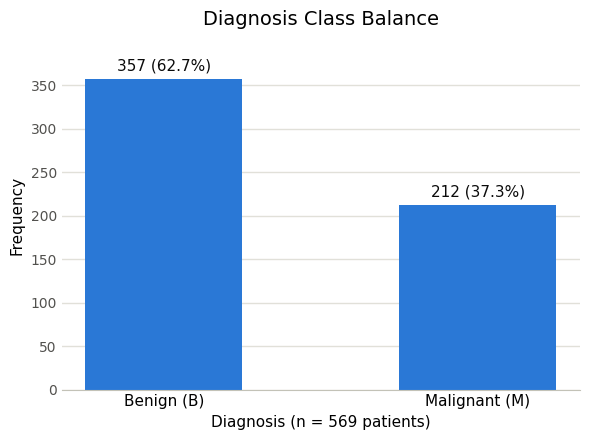

In [39]:
# Run this code

# Plot diagnosis class balance
# Convert PySpark DataFrame to pandas DataFrame for plotting
diagnosis_counts_pd = diagnosis_counts.toPandas()

labels = diagnosis_counts_pd["diagnosis"].map({"B": "Benign (B)", "M": "Malignant (M)"})
counts = diagnosis_counts_pd["count"]
total = counts.sum()

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(labels, counts, width=0.5, color="#2a78d6", zorder=2)

# Label each bar with its count and its share of all patients
ax.bar_label(bars, labels=[f"{c:,} ({c / total:.1%})" for c in counts],
             padding=4, fontsize=11, color="#0b0b0b")

ax.set_title("Diagnosis Class Balance", fontsize=14, pad=12)
ax.set_xlabel(f"Diagnosis (n = {total:,} patients)", fontsize=11)
ax.set_ylabel("Frequency", fontsize=11)
ax.tick_params(axis="x", labelsize=11, length=0)
ax.tick_params(axis="y", labelsize=10, colors="#52514e", length=0)

# Light horizontal gridlines only, behind the bars; drop the box around the plot
ax.yaxis.grid(True, color="#e1e0d9", linewidth=1)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.margins(y=0.12)  # headroom so the bar labels aren't clipped

plt.tight_layout()
plt.show()

### Step 6

Hospitals often look for trends, such as average tumor sizes, across different patient groups. Aggregating the data allows you to provide actionable insights, just as hospital administrators use statistics to guide resource allocation and policy decisions.

**Use .describe() to see statistics for each feature, which will help you understand the ranges and distributions of the data.**

**Then use the 'pyspark.sql.functions' of 'min' and 'max' to find the**
* **maximum of the `compactness_mean`**
* **minimum of the `smoothness_mean`**

**Take the difference of the `max_compactness_mean` and `min_smoothness_mean`.**

In [40]:
# Run this code

# Summary statistics
df.describe().show()

26/10/18 11:54:39 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: id, diagnosis, radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, perimeter_se, area_se, smoothness_se, compactness_se, concavity_se, concave points_se, symmetry_se, fractal_dimension_se, radius_worst, texture_worst, perimeter_worst, area_worst, smoothness_worst, compactness_worst, concavity_worst, concave points_worst, symmetry_worst, fractal_dimension_worst, 
 Schema: id, diagnosis, radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean, radius_se, texture_se, perimeter_se, area_se, smoothness_se, compactness_se, concavity_se, concave points_se, symmetry_se, fractal_dimension_se, radius_worst, texture_worst, perimeter_worst, area_worst, smoothness_wor

+-------+--------------------+---------+------------------+-----------------+-----------------+-----------------+--------------------+-------------------+-------------------+--------------------+--------------------+----------------------+------------------+------------------+------------------+-----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------------+------------------+------------------+-----------------+--------------------+-------------------+-------------------+--------------------+-------------------+-----------------------+----+
|summary|                  id|diagnosis|       radius_mean|     texture_mean|   perimeter_mean|        area_mean|     smoothness_mean|   compactness_mean|     concavity_mean| concave points_mean|       symmetry_mean|fractal_dimension_mean|         radius_se|        texture_se|      perimeter_se|          area_se|       smoothness_se|      compactness_

In [41]:
#CodeGrade step6
# Max compactness_mean and min smoothness_mean via pyspark.sql.functions max/min
extremes = df.select(
    max("compactness_mean").alias("max_compactness_mean"),
    min("smoothness_mean").alias("min_smoothness_mean"),
).collect()[0]

max_compactness_mean = extremes["max_compactness_mean"]
min_smoothness_mean = extremes["min_smoothness_mean"]
compactness_smoothness_difference = max_compactness_mean - min_smoothness_mean
compactness_smoothness_difference

0.29277

### Step 7

Identifying and creating meaningful features is akin to a doctor refining diagnostic criteria. By engineering new features, you're preparing the data for predictive models, making the analysis more precise and impactful.


**Let's suppose that you have reason to believe that the product of the 'radius_mean', 'texture_mean', and 'perimeter_mean' is meaningful to verify a diagnosis of Benign.**

**Thus, use SQL Query to compute:**
*   **Average of 'radius_mean', 'texture_mean', and 'perimeter_mean' for each diagnosis (all three rounded to two decimal places) only for the Benign case**
*  ** Return only the product of the these three rounded means**

In [42]:
#CodeGrade step07
# Product of the benign averages of radius, texture, and perimeter, each rounded to 2 decimals
product_of_means = spark.sql("""
    SELECT ROUND(AVG(radius_mean), 2)
         * ROUND(AVG(texture_mean), 2)
         * ROUND(AVG(perimeter_mean), 2) AS product_of_means
    FROM breast_cancer
    WHERE diagnosis = 'B'
""").collect()[0]["product_of_means"]
product_of_means

16990.71552

### Step 8

Let's suppose that you have reason to believe that the average of the ratio of the `radius_mean` and the `perimeter_mean` are meaningful for the Malignant cases.

**Thus, use SQL Query to compute:**

*   **Average of the ration of the `radius_mean` and the `perimeter_mean` only for the Malignant cases**
*   **Round this to two decimal places and call the result `mean_radius_perimeter_ratio`**


In [43]:
# CodeGrade step8
# Average radius/perimeter ratio for malignant cases, rounded to 2 decimals
mean_radius_perimeter_ratio = spark.sql("""
    SELECT ROUND(AVG(radius_mean / perimeter_mean), 2) AS mean_radius_perimeter_ratio
    FROM breast_cancer
    WHERE diagnosis = 'M'
""").collect()[0]["mean_radius_perimeter_ratio"]
mean_radius_perimeter_ratio

0.15

### Step 9

 Before deploying a diagnostic model, it’s crucial to ensure its reliability by looking at its sum of standard devations.

** Use a query to find `sum_of_stddevs`, where that is the sum of the standard deviation of the `symmetry_mean` and `fractal_dimension_mean' **

In [44]:
# CodeGrade step9
# Spark's STDDEV is the sample standard deviation
sum_of_stddevs = spark.sql("""
    SELECT STDDEV(symmetry_mean) + STDDEV(fractal_dimension_mean) AS sum_of_stddevs
    FROM breast_cancer
""").collect()[0]["sum_of_stddevs"]
sum_of_stddevs

0.03447464413112017

### Step 10

Close the spark session, where verification will result in the output of 'yes'



In [45]:
# CodeGrade step10

# Close the Spark session
spark.stop()

# Verify the session is closed: stop() clears the SparkContext's Java handle
def is_spark_stopped(spark):
    try:
        if spark.sparkContext._jsc is None:
            return "yes"
    except Exception:
        return "yes"
    return "no"

spark_stopped = is_spark_stopped(spark)
spark_stopped

'yes'